## Целочисленное программирование

In [1]:
import pyomo.environ as pyo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Создаем решатель HiGHS. Он поддерживает линейные задачи.
solver = pyo.SolverFactory("appsi_highs")
# Проверяем, что решатель доступен.
print("Решатель доступен:", solver.available())

Решатель доступен: True


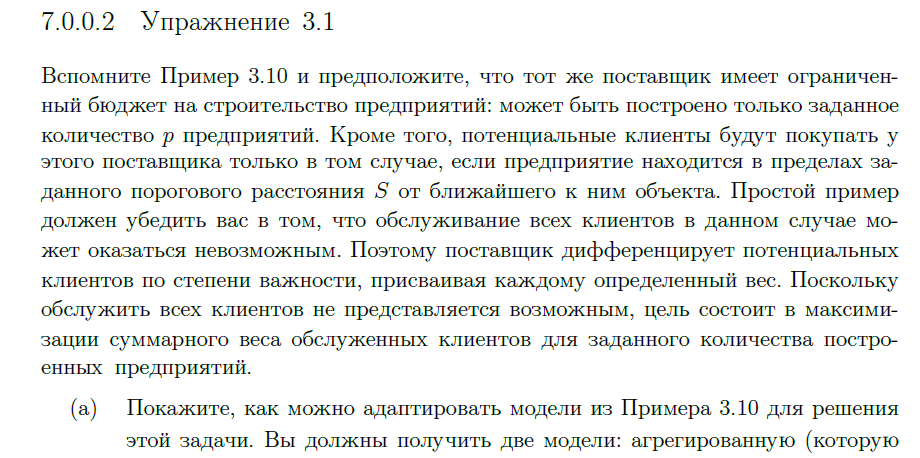

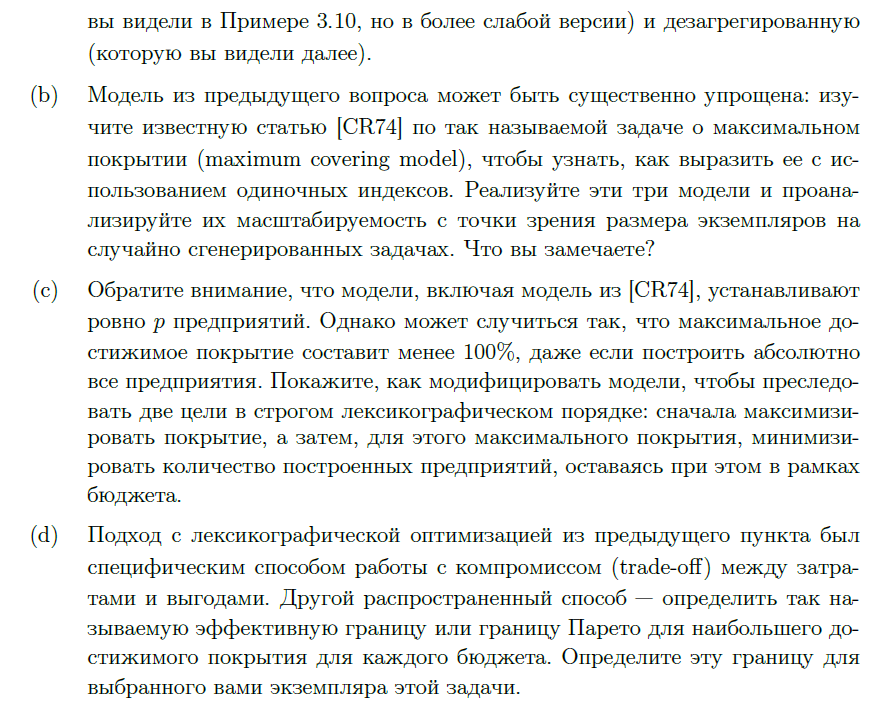

### Формализация 3.1 (Maximum Covering)

**Смысл.** Можно открыть не больше \(p\) предприятий. Клиент \(i\) покрыт, только если есть предприятие в радиусе \(S\). Цель — максимизировать суммарный вес покрытых клиентов.

**Обозначения.**
- \(x_j\in\{0,1\}\) — открыто ли предприятие в месте \(j\);
- \(z_i\in\{0,1\}\) — покрыт ли клиент \(i\);
- \(N_i=\{j:\ d_{ij}\le S\}\) — места, достаточно близкие к клиенту \(i\);
- \(w_i\) — вес клиента \(i\).

**(a) Одноиндексная / агрегированная модель (Church–ReVelle):**
$$
\begin{align*}
\max\quad &\sum_i w_i z_i\\
\text{s.t.}\quad &\sum_j x_j \le p,\\
& z_i \le \sum_{j\in N_i} x_j &&\forall i,\\
& x_j,z_i\in\{0,1\}.
\end{align*}
$$

**Дезагрегированная модель** добавляет назначения \(y_{ij}\in\{0,1\}\):
$$
y_{ij}\le x_j\ (j\in N_i),\quad
\sum_{j\in N_i} y_{ij}\ge z_i,\quad
\sum_{j\in N_i} y_{ij}\le |N_i|\,z_i.
$$

**(b)** Сравниваем размер и время решения трёх формулировок на случайных экземплярах.

**(c) Лексикография:** сначала \(\max\sum w_i z_i\), затем при том же покрытии \(\min\sum x_j\).

**(d) Парето:** для каждого бюджета \(p=1,2,\ldots\) решаем задачу покрытия и строим кривую «бюджет → вес».


In [2]:
# Демонстрационные исходные данные.
np.random.seed(10)  # фиксируем случайность, чтобы пример воспроизводился

n_facilities = 12   # число возможных мест для предприятия
n_clients = 30      # число потенциальных клиентов
p = 4               # максимум предприятий, которые можно построить
S = 25              # максимальное расстояние до клиента

# Координаты возможных предприятий и клиентов на условной плоскости.
facility_xy = np.random.uniform(0, 100, size=(n_facilities, 2))
client_xy = np.random.uniform(0, 100, size=(n_clients, 2))

# Вес каждого клиента: насколько важно его обслужить.
weights = np.random.randint(1, 11, size=n_clients)

# Расстояние от каждого возможного предприятия до каждого клиента.
dist = np.zeros((n_facilities, n_clients))
for i in range(n_facilities):
    for j in range(n_clients):
        dist[i, j] = np.linalg.norm(facility_xy[i] - client_xy[j])

# eligible[i, j] = 1, если предприятие i может покрыть клиента j.
eligible = {(i, j): int(dist[i, j] <= S)
            for i in range(n_facilities) for j in range(n_clients)}

# Список мест, которые способны покрыть каждого клиента.
covering_facilities = {
    j: [i for i in range(n_facilities) if eligible[i, j] == 1]
    for j in range(n_clients)
}

In [3]:
# Пункт (a). Модель 1: агрегированная формулировка.
def maximum_cover_aggregated(p, weights, covering_facilities, n_facilities):
    # Создаём пустую модель оптимизации.
    m = pyo.ConcreteModel(name="Maximum_cover_aggregated")

    # Индексы возможных предприятий и клиентов.
    m.I = pyo.RangeSet(0, n_facilities - 1)
    m.J = pyo.RangeSet(0, len(weights) - 1)

    # Бинарные переменные: строить ли предприятие и обслуживается ли клиент.
    m.x = pyo.Var(m.I, domain=pyo.Binary)
    m.y = pyo.Var(m.J, domain=pyo.Binary)

    # Максимизируем сумму весов обслуженных клиентов.
    m.obj = pyo.Objective(
        expr=sum(weights[j] * m.y[j] for j in m.J),
        sense=pyo.maximize
    )

    # Строим не более p предприятий.
    m.facility_limit = pyo.Constraint(
        expr=sum(m.x[i] for i in m.I) <= p
    )

    # Клиент может считаться обслуженным только если его покрывает хотя бы одно
    # построенное предприятие.
    def coverage_rule(m, j):
        possible = covering_facilities[j]
        if len(possible) == 0:
            return m.y[j] == 0
        return m.y[j] <= sum(m.x[i] for i in possible)

    m.coverage = pyo.Constraint(m.J, rule=coverage_rule)
    return m

m31_agg = maximum_cover_aggregated(p, weights, covering_facilities, n_facilities)
solver.solve(m31_agg)
print("Агрегированная модель: вес покрытия =", pyo.value(m31_agg.obj))
print("Построить в местах:", [i for i in m31_agg.I if pyo.value(m31_agg.x[i]) > 0.5])

Агрегированная модель: вес покрытия = 141.0
Построить в местах: [6, 7, 8, 11]


In [4]:
# Пункт (a). Модель 2: дезагрегированная формулировка.
def maximum_cover_disaggregated(p, weights, eligible, n_facilities, n_clients):
    # Создаём пустую модель оптимизации.
    m = pyo.ConcreteModel(name="Maximum_cover_disaggregated")

    # Индексы возможных предприятий и клиентов.
    m.I = pyo.RangeSet(0, n_facilities - 1)
    m.J = pyo.RangeSet(0, n_clients - 1)

    m.x = pyo.Var(m.I, domain=pyo.Binary)  # построение предприятия
    m.y = pyo.Var(m.J, domain=pyo.Binary)  # факт обслуживания клиента
    m.z = pyo.Var(m.I, m.J, domain=pyo.Binary)  # назначение клиента предприятию

    # Максимизируем сумму весов обслуженных клиентов.
    m.obj = pyo.Objective(
        expr=sum(weights[j] * m.y[j] for j in m.J),
        sense=pyo.maximize
    )

    # Строим не более p предприятий.
    m.facility_limit = pyo.Constraint(expr=sum(m.x[i] for i in m.I) <= p)

    # Назначение возможно только если предприятие построено и клиент находится
    # в пределах порогового расстояния.
    def assignment_rule(m, i, j):
        if eligible[i, j] == 0:
            return m.z[i, j] == 0
        return m.z[i, j] <= m.x[i]

    m.assignment = pyo.Constraint(m.I, m.J, rule=assignment_rule)

    # Если клиент обслужен, ему должно соответствовать хотя бы одно назначение.
    # Обратно: если есть назначение, клиент обязательно считается обслуженным.
    def client_covered_rule(m, j):
        return sum(m.z[i, j] for i in m.I) >= m.y[j]
    m.client_covered = pyo.Constraint(m.J, rule=client_covered_rule)

    def assigned_means_covered_rule(m, j):
        return sum(m.z[i, j] for i in m.I) <= len(m.I) * m.y[j]
    m.assigned_means_covered = pyo.Constraint(m.J, rule=assigned_means_covered_rule)
    return m

m31_dis = maximum_cover_disaggregated(p, weights, eligible, n_facilities, n_clients)
solver.solve(m31_dis)
print("Дезагрегированная модель: вес покрытия =", pyo.value(m31_dis.obj))
print("Построить в местах:", [i for i in m31_dis.I if pyo.value(m31_dis.x[i]) > 0.5])

Дезагрегированная модель: вес покрытия = 141.0
Построить в местах: [6, 7, 8, 11]


In [5]:
# Пункт (a). Модель 3: классическая однoиндексная модель максимального покрытия.
def maximum_cover_one_index(p, weights, eligible, n_facilities, n_clients):
    # Создаём пустую модель оптимизации.
    m = pyo.ConcreteModel(name="Maximum_cover_one_index")

    # Индексы возможных предприятий и клиентов.
    m.I = pyo.RangeSet(0, n_facilities - 1)
    m.J = pyo.RangeSet(0, n_clients - 1)

    # Бинарные переменные: строить ли предприятие и обслуживается ли клиент.
    m.x = pyo.Var(m.I, domain=pyo.Binary)
    m.y = pyo.Var(m.J, domain=pyo.Binary)

    # Максимизируем сумму весов обслуженных клиентов.
    m.obj = pyo.Objective(
        expr=sum(weights[j] * m.y[j] for j in m.J),
        sense=pyo.maximize
    )

    # Строим не более p предприятий.
    m.limit = pyo.Constraint(expr=sum(m.x[i] for i in m.I) <= p)

    def coverage_rule(m, j):
        return m.y[j] <= sum(eligible[i, j] * m.x[i] for i in m.I)
    m.coverage = pyo.Constraint(m.J, rule=coverage_rule)
    return m

m31_one = maximum_cover_one_index(p, weights, eligible, n_facilities, n_clients)
solver.solve(m31_one)
print("Одноиндексная модель: вес покрытия =", pyo.value(m31_one.obj))
print("Построить в местах:", [i for i in m31_one.I if pyo.value(m31_one.x[i]) > 0.5])

Одноиндексная модель: вес покрытия = 141.0
Построить в местах: [6, 7, 8, 11]


In [6]:
# Пункт (b). Сравнение размеров моделей на базовом примере.
def model_size(model):
    variables = sum(1 for _ in model.component_data_objects(pyo.Var, active=True))
    constraints = sum(1 for _ in model.component_data_objects(pyo.Constraint, active=True))
    return variables, constraints

comparison = pd.DataFrame([
    ("Агрегированная", *model_size(m31_agg)),
    ("Дезагрегированная", *model_size(m31_dis)),
    ("Одноиндексная", *model_size(m31_one)),
], columns=["Модель", "Число переменных", "Число ограничений"])
display(comparison)

# Масштабируемость: случайные экземпляры разного размера, замер времени solve.
import time

def generate_cover_instance(n_fac, n_cli, p_local, S_local, seed):
    rng = np.random.default_rng(seed)
    fac_xy = rng.uniform(0, 100, size=(n_fac, 2))
    cli_xy = rng.uniform(0, 100, size=(n_cli, 2))
    w = rng.integers(1, 11, size=n_cli)
    elig = {}
    for i in range(n_fac):
        for j in range(n_cli):
            elig[i, j] = int(np.linalg.norm(fac_xy[i] - cli_xy[j]) <= S_local)
    covering = {j: [i for i in range(n_fac) if elig[i, j] == 1] for j in range(n_cli)}
    return w, elig, covering

def timed_solve(build_fn):
    model = build_fn()
    t0 = time.perf_counter()
    solver.solve(model)
    return time.perf_counter() - t0, model_size(model)

scale_rows = []
for n_fac, n_cli, p_local in [(8, 20, 3), (12, 30, 4), (20, 50, 5), (30, 80, 6)]:
    w, elig, covering = generate_cover_instance(n_fac, n_cli, p_local, 25, seed=100 + n_fac)
    builders = {
        "Агрегированная": lambda w=w, covering=covering, n_fac=n_fac, p_local=p_local:
            maximum_cover_aggregated(p_local, w, covering, n_fac),
        "Дезагрегированная": lambda w=w, elig=elig, n_fac=n_fac, n_cli=n_cli, p_local=p_local:
            maximum_cover_disaggregated(p_local, w, elig, n_fac, n_cli),
        "Одноиндексная": lambda w=w, elig=elig, n_fac=n_fac, n_cli=n_cli, p_local=p_local:
            maximum_cover_one_index(p_local, w, elig, n_fac, n_cli),
    }
    for name, builder in builders.items():
        seconds, (n_vars, n_cons) = timed_solve(builder)
        scale_rows.append({
            "n_fac": n_fac,
            "n_cli": n_cli,
            "Модель": name,
            "Переменные": n_vars,
            "Ограничения": n_cons,
            "Время, с": round(seconds, 4),
        })

scalability = pd.DataFrame(scale_rows)
display(scalability)

print("Наблюдения:")
print("- Агрегированная и одноиндексная имеют одинаковый порядок размера O(n_fac + n_cli).")
print("- Дезагрегированная растёт как O(n_fac * n_cli) по переменным и ограничениям.")
print("- На крупных экземплярах дезагрегированная заметно медленнее двух компактных формулировок.")

,Модель,Число переменных,Число ограничений
0,Агрегированная,42,31
1,Дезагрегированная,402,421
2,Одноиндексная,42,31


,n_fac,n_cli,Модель,Переменные,Ограничения,"Время, с"
0,8,20,Агрегированная,28,21,0.0608
1,8,20,Дезагрегированная,188,201,0.0754
2,8,20,Одноиндексная,28,21,0.0429
3,12,30,Агрегированная,42,31,0.0568
4,12,30,Дезагрегированная,402,421,0.0777
5,12,30,Одноиндексная,42,31,0.0632
6,20,50,Агрегированная,70,51,0.0648
7,20,50,Дезагрегированная,1070,1101,0.1331
8,20,50,Одноиндексная,70,51,0.0478
9,30,80,Агрегированная,110,81,0.0527


Наблюдения:
- Агрегированная и одноиндексная имеют одинаковый порядок размера O(n_fac + n_cli).
- Дезагрегированная растёт как O(n_fac * n_cli) по переменным и ограничениям.
- На крупных экземплярах дезагрегированная заметно медленнее двух компактных формулировок.


In [7]:
# Пункт (с). Лексиграфическая оптимизация по шагам.
# Первый этап: находим максимально возможный вес покрытия.
m31_lex = maximum_cover_one_index(p, weights, eligible, n_facilities, n_clients)
solver.solve(m31_lex)
best_coverage = round(pyo.value(m31_lex.obj))

# Второй этап: фиксируем максимальный вес и минимизируем количество построенных предприятий.
m31_lex.obj.deactivate()
m31_lex.keep_coverage = pyo.Constraint(
    expr=sum(weights[j] * m31_lex.y[j] for j in m31_lex.J) == best_coverage
)
m31_lex.min_facilities = pyo.Objective(
    expr=sum(m31_lex.x[i] for i in m31_lex.I),
    sense=pyo.minimize
)
solver.solve(m31_lex)

print("Максимальный вес покрытия:", best_coverage)
print("Минимальное число предприятий при этом покрытии:",
      sum(round(pyo.value(m31_lex.x[i])) for i in m31_lex.I))

Максимальный вес покрытия: 141
Минимальное число предприятий при этом покрытии: 4


,Число предприятий,Вес покрытия
0,1,47.0
1,2,87.0
2,3,121.0
3,4,141.0
4,5,162.0
5,6,164.0
6,7,164.0
7,8,164.0
8,9,164.0
9,10,164.0


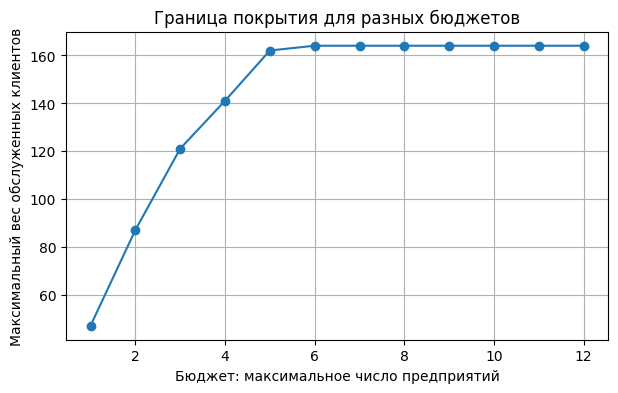

In [8]:
# Пункт (d). Граница Парето "бюджет-покрытие"
pareto_rows = []
for budget in range(1, n_facilities + 1):
    model = maximum_cover_one_index(
        budget, weights, eligible, n_facilities, n_clients
    )
    solver.solve(model)
    covered_weight = pyo.value(model.obj)
    pareto_rows.append((budget, covered_weight))

pareto = pd.DataFrame(pareto_rows, columns=["Число предприятий", "Вес покрытия"])
display(pareto)

plt.figure(figsize=(7, 4))
plt.plot(pareto["Число предприятий"], pareto["Вес покрытия"], marker="o")
plt.xlabel("Бюджет: максимальное число предприятий")
plt.ylabel("Максимальный вес обслуженных клиентов")
plt.title("Граница покрытия для разных бюджетов")
plt.grid(True)
plt.show()

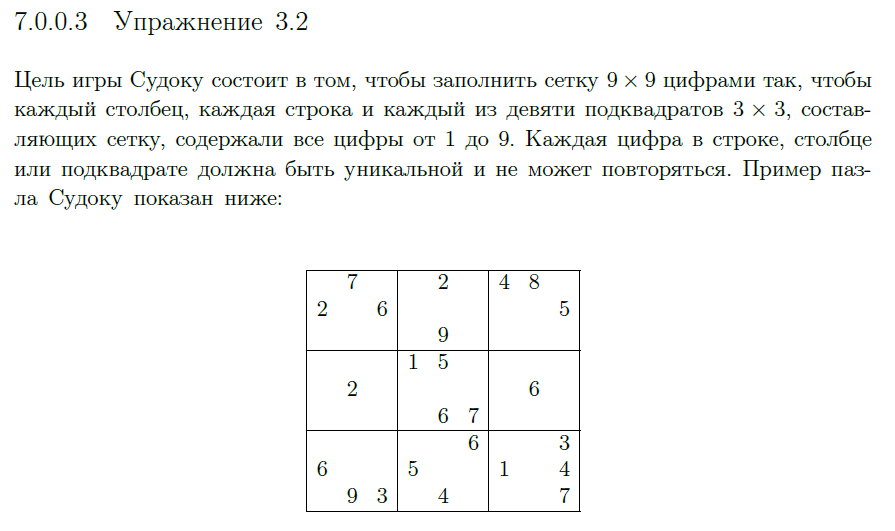

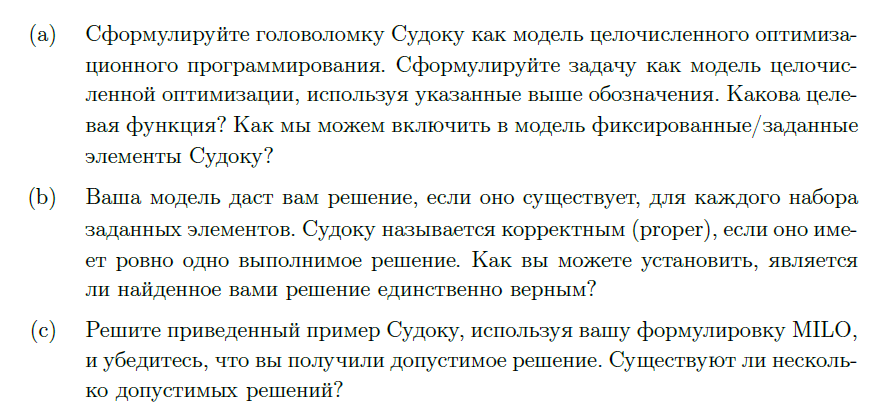

### Формализация 3.2 (Судоку)

**Смысл.** Заполнить сетку \(9\times 9\) цифрами \(1..9\) так, чтобы в каждой строке, столбце и блоке \(3\times 3\) каждая цифра встречалась ровно один раз. Заданные клетки фиксированы.

**Переменные.** \(x_{rck}\in\{0,1\}\): в клетке \((r,c)\) стоит цифра \(k\).

**Модель (задача выполнимости, цель фиктивная):**
$$
\begin{align*}
\min\quad &0\\
\text{s.t.}\quad &\sum_{k=1}^9 x_{rck}=1 &&\forall r,c,\\
&\sum_{c=1}^9 x_{rck}=1 &&\forall r,k,\\
&\sum_{r=1}^9 x_{rck}=1 &&\forall c,k,\\
&\sum_{(r,c)\in B} x_{rck}=1 &&\forall\text{ блок }B,\ \forall k,\\
& x_{rck}=1 &&\text{для заданных клеток},\\
& x_{rck}\in\{0,1\}.
\end{align*}
$$

**Единственность.** Найти одно решение \(s\), добавить отсечение \(\sum_{r,c} x_{r,c,s_{rc}}\le 80\) и решить снова: если снова feasible — решений ≥ 2.


In [9]:
# Нули означают пустые клетки.
sudoku = [
    [0, 7, 0, 0, 2, 0, 4, 8, 0],
    [2, 0, 6, 0, 0, 0, 0, 0, 5],
    [0, 0, 0, 0, 9, 0, 0, 0, 0],
    [0, 0, 0, 1, 5, 0, 0, 0, 0],
    [0, 2, 0, 0, 0, 0, 0, 6, 0],
    [0, 0, 0, 0, 6, 7, 0, 0, 0],
    [0, 0, 0, 0, 0, 6, 0, 0, 3],
    [6, 0, 0, 5, 0, 0, 1, 0, 4],
    [0, 9, 3, 0, 4, 0, 0, 0, 7],
]

In [10]:
# Переменные и ограничения.
def build_sudoku_model(puzzle, forbidden_solution=None):
    # Создаём модель Судоку.
    m = pyo.ConcreteModel(name="Sudoku")

    # Строки, столбцы и цифры нумеруются от 1 до 9.
    m.R = pyo.RangeSet(1, 9)
    m.C = pyo.RangeSet(1, 9)
    m.K = pyo.RangeSet(1, 9)

    # x[r,c,k] = 1, если в клетке (r,c) стоит цифра k.
    m.x = pyo.Var(m.R, m.C, m.K, domain=pyo.Binary)

    # В каждой клетке должна быть ровно одна цифра.
    m.one_digit = pyo.Constraint(
        m.R, m.C,
        rule=lambda m, r, c: sum(m.x[r, c, k] for k in m.K) == 1
    )

    # Каждая цифра ровно один раз в каждой строке.
    m.row_rule = pyo.Constraint(
        m.R, m.K,
        rule=lambda m, r, k: sum(m.x[r, c, k] for c in m.C) == 1
    )

    # Каждая цифра ровно один раз в каждом столбце.
    m.col_rule = pyo.Constraint(
        m.C, m.K,
        rule=lambda m, c, k: sum(m.x[r, c, k] for r in m.R) == 1
    )

    # Каждая цифра ровно один раз в каждом квадрате 3 на 3.
    m.box_rule = pyo.ConstraintList()
    for k in range(1, 10):
        for box_r in (1, 4, 7):
            for box_c in (1, 4, 7):
                m.box_rule.add(
                    sum(m.x[r, c, k]
                        for r in range(box_r, box_r + 3)
                        for c in range(box_c, box_c + 3)) == 1
                )

    # Фиксируем заданные в условии цифры.
    m.givens = pyo.ConstraintList()
    for r in range(9):
        for c in range(9):
            digit = puzzle[r][c]
            if digit != 0:
                m.givens.add(m.x[r + 1, c + 1, digit] == 1)

    # Если передали найденное решение, запрещаем повторно получить точно его.
    # Для 81 клетки сумма выбранных в этом решении переменных должна быть <= 80.
    if forbidden_solution is not None:
        m.exclude_previous = pyo.Constraint(
            expr=sum(
                m.x[r + 1, c + 1, forbidden_solution[r][c]]
                for r in range(9) for c in range(9)
            ) <= 80
        )

    # Судоку — задача на выполнимость, поэтому можно использовать нулевую цель.
    m.obj = pyo.Objective(expr=0, sense=pyo.minimize)
    return m


def read_sudoku_solution(model):
    # Переводим бинарные переменные обратно в привычную таблицу цифр.
    solution = []
    for r in range(1, 10):
        row = []
        for c in range(1, 10):
            digit = next(k for k in range(1, 10)
                         if pyo.value(model.x[r, c, k]) > 0.5)
            row.append(digit)
        solution.append(row)
    return solution

m_sudoku = build_sudoku_model(sudoku)
result = solver.solve(m_sudoku, load_solutions=False)
print("Статус решателя:", result.solver.termination_condition)

if result.solver.termination_condition == pyo.TerminationCondition.optimal:
    # Загружаем решение только после подтверждения, что оно найдено.
    m_sudoku.solutions.load_from(result)
    solution = read_sudoku_solution(m_sudoku)
    display(pd.DataFrame(solution, index=range(1, 10), columns=range(1, 10)))

Статус решателя: optimal


,1,2,3,4,5,6,7,8,9
1,5,7,9,3,2,1,4,8,6
2,2,1,6,7,8,4,9,3,5
3,3,4,8,6,9,5,7,1,2
4,8,6,4,1,5,2,3,7,9
5,7,2,1,4,3,9,5,6,8
6,9,3,5,8,6,7,2,4,1
7,4,5,7,9,1,6,8,2,3
8,6,8,2,5,7,3,1,9,4
9,1,9,3,2,4,8,6,5,7


In [11]:
# Проверка, есть ли второе решение.
# Проверка единственности: ищем другое решение, запретив найденное.
# Если первое решение не найдено, этот шаг запускать нельзя.
if 'solution' in globals():
    m_sudoku_second = build_sudoku_model(sudoku, forbidden_solution=solution)
    result_second = solver.solve(m_sudoku_second)

    if result_second.solver.termination_condition == pyo.TerminationCondition.optimal:
        print("Есть как минимум два решения. Второе решение:")
        solution2 = read_sudoku_solution(m_sudoku_second)
        display(pd.DataFrame(solution2, index=range(1, 10), columns=range(1, 10)))
    else:
        print("Другого решения нет: найденное решение единственное.")

Есть как минимум два решения. Второе решение:


,1,2,3,4,5,6,7,8,9
1,9,7,1,3,2,5,4,8,6
2,2,3,6,8,7,4,9,1,5
3,8,5,4,6,9,1,3,7,2
4,4,6,8,1,5,2,7,3,9
5,7,2,9,4,8,3,5,6,1
6,3,1,5,9,6,7,2,4,8
7,5,4,2,7,1,6,8,9,3
8,6,8,7,5,3,9,1,2,4
9,1,9,3,2,4,8,6,5,7


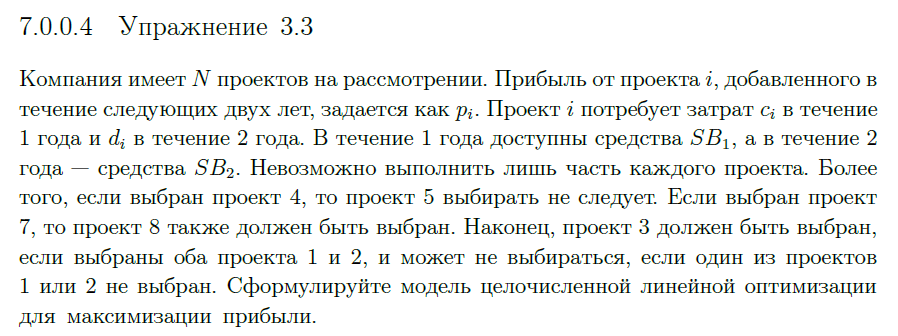

### Формализация 3.3 (Выбор проектов)

**Смысл.** Выбрать подмножество проектов с max прибылью при бюджетах двух лет и логических связях.

**Переменные.** \(x_i\in\{0,1\}\) — выбран ли проект \(i\).

$$
\begin{align*}
\max\quad &\sum_{i=1}^N p_i x_i\\
\text{s.t.}\quad &\sum_i c_i x_i \le SB_1,\\
&\sum_i d_i x_i \le SB_2,\\
& x_4 + x_5 \le 1 &&\text{(не оба 4 и 5)},\\
& x_7 \le x_8 &&\text{(7 ⇒ 8)},\\
& x_1 + x_2 - 1 \le x_3,\quad x_3\le x_1,\quad x_3\le x_2 &&\text{(}x_3=x_1\land x_2\text{)},\\
& x_i\in\{0,1\}.
\end{align*}
$$


In [12]:
# Демонстрационные значения
N = 8
profit = {i: v for i, v in enumerate([8, 6, 9, 5, 7, 4, 10, 3], start=1)}
cost_year1 = {i: v for i, v in enumerate([4, 3, 5, 2, 4, 2, 6, 2], start=1)}
cost_year2 = {i: v for i, v in enumerate([3, 4, 2, 3, 2, 4, 3, 2], start=1)}
SB1, SB2 = 15, 14

m33 = pyo.ConcreteModel(name="Project_selection")
m33.I = pyo.RangeSet(1, N)
m33.x = pyo.Var(m33.I, domain=pyo.Binary)

m33.obj = pyo.Objective(expr=sum(profit[i] * m33.x[i] for i in m33.I),
                        sense=pyo.maximize)
m33.budget1 = pyo.Constraint(expr=sum(cost_year1[i] * m33.x[i] for i in m33.I) <= SB1)
m33.budget2 = pyo.Constraint(expr=sum(cost_year2[i] * m33.x[i] for i in m33.I) <= SB2)

# Если проект 4 выбран, проект 5 не должен быть выбран.
m33.rule_4_5 = pyo.Constraint(expr=m33.x[4] + m33.x[5] <= 1)

# Выбор проекта 7 требует выбора проекта 8.
m33.rule_7_8 = pyo.Constraint(expr=m33.x[7] <= m33.x[8])

# Проект 3 выбирается тогда и только тогда, когда выбраны оба проекта 1 и 2:
# (1 ∧ 2) ⇒ 3  и  3 ⇒ 1,  3 ⇒ 2.
m33.rule_1_2_implies_3 = pyo.Constraint(expr=m33.x[1] + m33.x[2] - 1 <= m33.x[3])
m33.rule_3_implies_1 = pyo.Constraint(expr=m33.x[3] <= m33.x[1])
m33.rule_3_implies_2 = pyo.Constraint(expr=m33.x[3] <= m33.x[2])

solver.solve(m33)
selected_33 = [i for i in m33.I if pyo.value(m33.x[i]) > 0.5]
print("Максимальная прибыль:", pyo.value(m33.obj))
print("Выбранные проекты:", selected_33)
print("Затраты год 1:", sum(cost_year1[i] for i in selected_33),
      "/ лимит", SB1)
print("Затраты год 2:", sum(cost_year2[i] for i in selected_33),
      "/ лимит", SB2)

Максимальная прибыль: 28.0
Выбранные проекты: [1, 2, 3, 4]
Затраты год 1: 14 / лимит 15
Затраты год 2: 12 / лимит 14


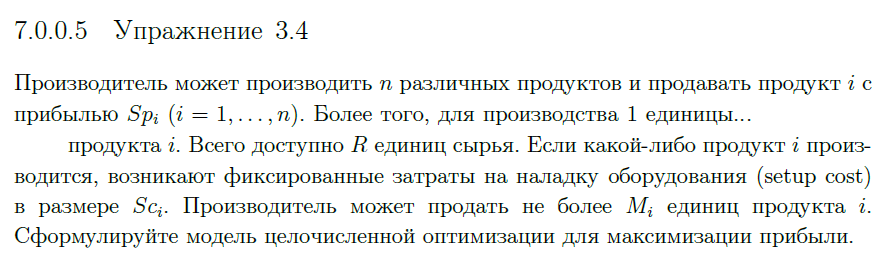

### Формализация 3.4 (Производство с setup-затратами)

**Смысл.** При выпуске продукта \(i\) платится фиксированная наладка \(s_i\) плюс удельная прибыль \(p_i\).

**Переменные.** \(q_i\ge 0\) — объём; \(y_i\in\{0,1\}\) — запускаем ли продукт \(i\).

$$
\begin{align*}
\max\quad &\sum_i \bigl(p_i q_i - s_i y_i\bigr)\\
\text{s.t.}\quad &\sum_i a_i q_i \le R &&\text{(сырьё)},\\
& q_i \le M_i y_i &&\forall i\quad\text{(Big-M / setup)},\\
& q_i\ge 0,\ y_i\in\{0,1\}.
\end{align*}
$$


In [13]:
# Демонстрационные данные
products = [1, 2, 3, 4]
profit = {1: 12, 2: 9, 3: 15, 4: 7}       # прибыль за единицу
resource = {1: 3, 2: 2, 3: 5, 4: 1}       # сырьё на единицу продукции
setup = {1: 20, 2: 15, 3: 25, 4: 10}      # фиксированные затраты запуска
M = {1: 20, 2: 25, 3: 10, 4: 30}          # максимальные продажи каждого продукта
R = 100                                    # доступное количество сырья

m34 = pyo.ConcreteModel(name="Production_with_setup_costs")
m34.I = pyo.Set(initialize=products)
m34.q = pyo.Var(m34.I, domain=pyo.NonNegativeIntegers)
m34.y = pyo.Var(m34.I, domain=pyo.Binary)

m34.obj = pyo.Objective(
    expr=sum(profit[i] * m34.q[i] - setup[i] * m34.y[i] for i in m34.I),
    sense=pyo.maximize
)
m34.raw_material = pyo.Constraint(
    expr=sum(resource[i] * m34.q[i] for i in m34.I) <= R
)
m34.sales_limit = pyo.Constraint(
    m34.I, rule=lambda m, i: m.q[i] <= M[i] * m.y[i]
)

solver.solve(m34)
print("Максимальная прибыль:", pyo.value(m34.obj))
for i in m34.I:
    print(f"Продукт {i}: объём = {pyo.value(m34.q[i]):.0f}, запуск = {pyo.value(m34.y[i]):.0f}")

Максимальная прибыль: 468.0
Продукт 1: объём = 8, запуск = 1
Продукт 2: объём = 23, запуск = 1
Продукт 3: объём = 0, запуск = 0
Продукт 4: объём = 30, запуск = 1


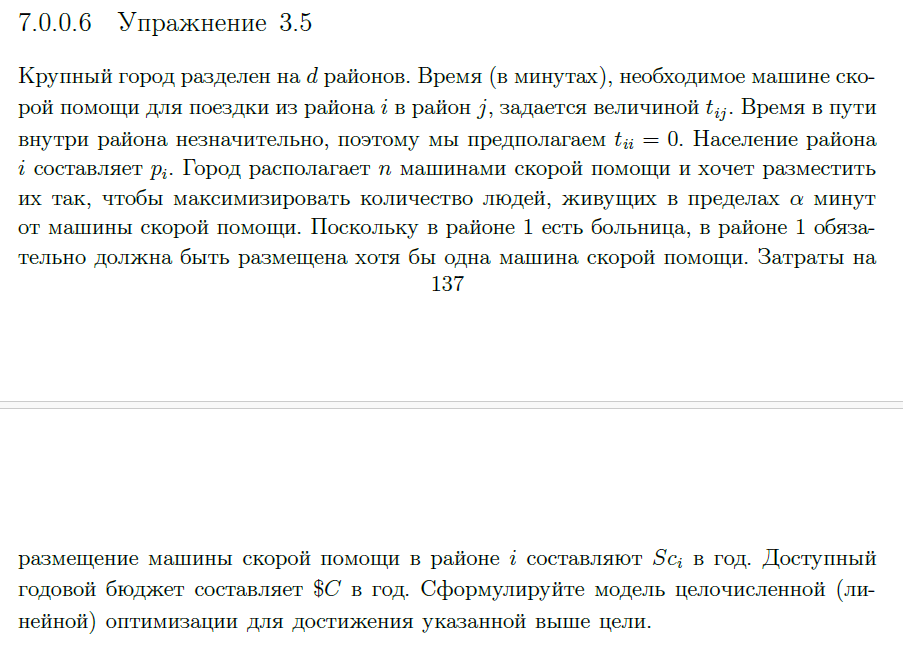

### Формализация 3.5 (Размещение скорой)

**Смысл.** Разместить до \(n\) машин при бюджете \(C\), обязательно ≥1 в районе больницы (район 1). Max население в зоне \(\alpha\) минут.

**Переменные.** \(x_i\in\mathbb{Z}_+\) — число машин в районе \(i\); \(y_j\in\{0,1\}\) — покрыт ли район \(j\).

$$
\begin{align*}
\max\quad &\sum_j \mathrm{pop}_j\, y_j\\
\text{s.t.}\quad &\sum_i x_i \le n,\\
&\sum_i \mathrm{cost}_i x_i \le C,\\
& x_1 \ge 1,\\
& y_j \le \sum_{i:\ t_{ij}\le\alpha} x_i &&\forall j,\\
& x_i\in\mathbb{Z}_+,\ y_j\in\{0,1\}.
\end{align*}
$$

**Лексикография в коде:** после max покрытия минимизируем \(\sum x_i\) при том же населении.


In [14]:
d = 6
n_ambulances = 4
alpha = 10
budget = 100

population = {1: 1200, 2: 900, 3: 1500, 4: 700, 5: 1100, 6: 800}
cost = {1: 25, 2: 20, 3: 30, 4: 15, 5: 20, 6: 18}

# Время поездки из района i в район j. Здесь демонстрационные значения.
travel = {
    (1,1):0, (1,2):5, (1,3):12, (1,4):14, (1,5):9, (1,6):16,
    (2,1):5, (2,2):0, (2,3):8, (2,4):10, (2,5):7, (2,6):12,
    (3,1):12,(3,2):8, (3,3):0, (3,4):6, (3,5):11,(3,6):7,
    (4,1):14,(4,2):10,(4,3):6, (4,4):0, (4,5):8, (4,6):5,
    (5,1):9, (5,2):7, (5,3):11,(5,4):8, (5,5):0, (5,6):10,
    (6,1):16,(6,2):12,(6,3):7, (6,4):5, (6,5):10,(6,6):0,
}
districts = list(range(1, d + 1))
can_cover = {j: [i for i in districts if travel[i, j] <= alpha] for j in districts}

m35 = pyo.ConcreteModel(name="Ambulance_location")
m35.I = pyo.Set(initialize=districts)
m35.J = pyo.Set(initialize=districts)
m35.x = pyo.Var(m35.I, domain=pyo.NonNegativeIntegers)
m35.y = pyo.Var(m35.J, domain=pyo.Binary)

m35.obj = pyo.Objective(
    expr=sum(population[j] * m35.y[j] for j in m35.J),
    sense=pyo.maximize
)
m35.number_limit = pyo.Constraint(expr=sum(m35.x[i] for i in m35.I) <= n_ambulances)
m35.budget_limit = pyo.Constraint(expr=sum(cost[i] * m35.x[i] for i in m35.I) <= budget)
m35.hospital = pyo.Constraint(expr=m35.x[1] >= 1)

# Район j покрыт, если в одном из районов, откуда до j не более alpha минут,
# размещена хотя бы одна машина.
def coverage_35(m, j):
    return m.y[j] <= sum(m.x[i] for i in can_cover[j])
m35.coverage = pyo.Constraint(m35.J, rule=coverage_35)

# Этап 1: максимизируем покрытое население.
solver.solve(m35)
best_population_35 = pyo.value(m35.obj)
print("Этап 1. Население под покрытием:", best_population_35)
print("Этап 1. Размещение (может быть избыточным):",
      {i: round(pyo.value(m35.x[i])) for i in m35.I})

# Этап 2: при том же покрытии минимизируем число машин.
m35.obj.deactivate()
m35.keep_coverage = pyo.Constraint(
    expr=sum(population[j] * m35.y[j] for j in m35.J) >= best_population_35 - 1e-6
)
m35.min_ambulances = pyo.Objective(
    expr=sum(m35.x[i] for i in m35.I),
    sense=pyo.minimize
)
solver.solve(m35)

placement_35 = {i: round(pyo.value(m35.x[i])) for i in m35.I}
covered_35 = [j for j in m35.J if pyo.value(m35.y[j]) > 0.5]
covered_pop_35 = sum(population[j] for j in covered_35)
print("Этап 2. Население под покрытием:", covered_pop_35)
print("Этап 2. Размещение машин:", placement_35)
print("Этап 2. Число машин:", sum(placement_35.values()))
print("Покрытые районы:", covered_35)
print("Затраты:", sum(cost[i] * placement_35[i] for i in m35.I), "/ бюджет", budget)

Этап 1. Население под покрытием: 6200.0
Этап 1. Размещение (может быть избыточным): {1: 1, 2: 0, 3: 0, 4: 3, 5: 0, 6: 0}
Этап 2. Население под покрытием: 6200
Этап 2. Размещение машин: {1: 1, 2: 0, 3: 0, 4: 1, 5: 0, 6: 0}
Этап 2. Число машин: 2
Покрытые районы: [1, 2, 3, 4, 5, 6]
Затраты: 40 / бюджет 100


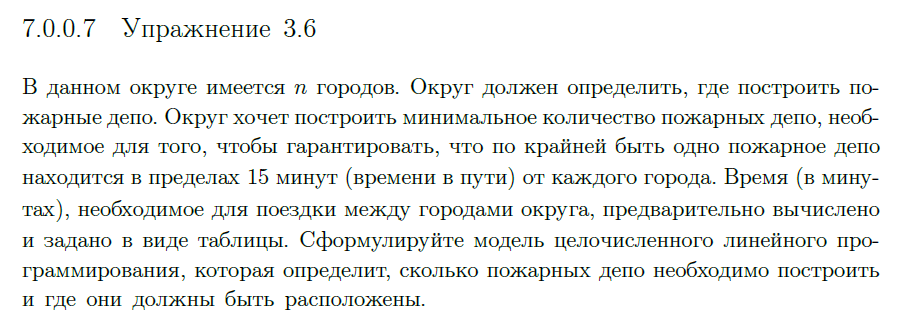

### Формализация 3.6 (Пожарные депо, set covering)

**Смысл.** Покрыть каждый город хотя бы одним депо в радиусе 15 минут; минимизировать число депо.

**Переменные.** \(x_i\in\{0,1\}\) — строить ли депо в городе \(i\).

$$
\begin{align*}
\min\quad &\sum_i x_i\\
\text{s.t.}\quad &\sum_{i:\ t_{ij}\le 15} x_i \ge 1 &&\forall j,\\
& x_i\in\{0,1\}.
\end{align*}
$$


In [15]:
n_towns = 6
towns = list(range(1, n_towns + 1))

# Демонстрационная матрица времени в пути (минуты).
time_fire = {
    (1,1):0, (1,2):7, (1,3):18, (1,4):20, (1,5):12, (1,6):25,
    (2,1):7, (2,2):0, (2,3):10, (2,4):14, (2,5):8,  (2,6):19,
    (3,1):18,(3,2):10,(3,3):0,  (3,4):6,  (3,5):13, (3,6):9,
    (4,1):20,(4,2):14,(4,3):6,  (4,4):0,  (4,5):11, (4,6):7,
    (5,1):12,(5,2):8, (5,3):13, (5,4):11, (5,5):0,  (5,6):15,
    (6,1):25,(6,2):19,(6,3):9,  (6,4):7,  (6,5):15, (6,6):0,
}

# Для каждого города j найдём города i, из которых до j можно доехать <= 15 минут.
covering_fire = {
    j: [i for i in towns if time_fire[i, j] <= 15]
    for j in towns
}

m36 = pyo.ConcreteModel(name="Fire_station_covering")
m36.I = pyo.Set(initialize=towns)
m36.J = pyo.Set(initialize=towns)
m36.x = pyo.Var(m36.I, domain=pyo.Binary)

m36.obj = pyo.Objective(expr=sum(m36.x[i] for i in m36.I), sense=pyo.minimize)

# Каждый город должен быть покрыт хотя бы одним выбранным городом-депо.
m36.cover_all = pyo.Constraint(
    m36.J,
    rule=lambda m, j: sum(m.x[i] for i in covering_fire[j]) >= 1
)

solver.solve(m36)
print("Минимальное число депо:", round(pyo.value(m36.obj)))
print("Города, где строятся депо:", [i for i in m36.I if pyo.value(m36.x[i]) > 0.5])

Минимальное число депо: 1
Города, где строятся депо: [5]


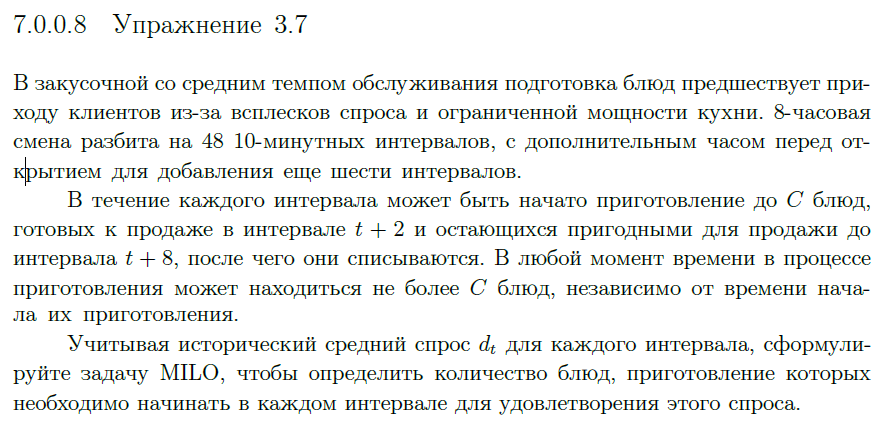

### Формализация 3.7 (Готовка блюд по интервалам)

**Смысл.** На горизонте \(T=54\) интервалов начинаем готовить \(q_u\) блюд в интервале \(u\) (ёмкость \(C\)). Блюдо готово с \(u+2\) до \(u+8\). Нужно покрыть спрос \(d_t\), минимизируя суммарный выпуск.

**Переменные.** \(q_u\in\mathbb{Z}_+\); \(s_{t,u}\in\mathbb{Z}_+\) — продажи партии \(u\) в момент \(t\) (только если \(u+2\le t\le u+8\)).

$$
\begin{align*}
\min\quad &\sum_u q_u\\
\text{s.t.}\quad & q_u \le C &&\forall u,\\
& q_t + q_{t-1} \le C &&\forall t\quad\text{(WIP)},\\
& \sum_{u:\ u+2\le t\le u+8} s_{t,u} = d_t &&\forall t,\\
& \sum_{t} s_{t,u} \le q_u &&\forall u,\\
& q_u,s_{t,u}\in\mathbb{Z}_+.
\end{align*}
$$


In [16]:
T = 54
C = 20

# Демонстрационный спрос для каждого из 54 интервалов.
np.random.seed(7)
demand = {t: int(np.random.randint(3, 13)) for t in range(T)}
# В первые два интервала блюд ещё не может быть готово, поскольку готовка
# занимает два интервала. Поэтому в этом примере спрос там равен нулю.
demand[0] = 0
demand[1] = 0

m37 = pyo.ConcreteModel(name="Meal_preparation")
m37.T = pyo.RangeSet(0, T - 1)

# q[u] — число блюд, приготовление которых начинается в интервале u.
m37.q = pyo.Var(m37.T, domain=pyo.NonNegativeIntegers)

# s[t,u] — сколько блюд, начатых в интервале u, продаётся в интервале t.
# Создаём только пары (t,u), где блюдо уже готово и ещё не просрочено.
sale_pairs = [(t, u) for t in range(T) for u in range(T)
              if u + 2 <= t <= u + 8]
m37.SALE_PAIRS = pyo.Set(dimen=2, initialize=sale_pairs)
m37.s = pyo.Var(m37.SALE_PAIRS, domain=pyo.NonNegativeIntegers)

# Минимизируем количество блюд, которые начинаем готовить.
m37.obj = pyo.Objective(expr=sum(m37.q[u] for u in m37.T),
                        sense=pyo.minimize)

# За один интервал можно начать готовить не более C блюд.
m37.start_capacity = pyo.Constraint(
    m37.T, rule=lambda m, u: m.q[u] <= C
)

# В процессе готовки блюдо находится два интервала.
# Поэтому в момент t одновременно готовятся блюда, запущенные в t и t-1.
def cooking_capacity_rule(m, t):
    active_starts = [u for u in (t - 1, t) if u >= 0]
    return sum(m.q[u] for u in active_starts) <= C
m37.cooking_capacity = pyo.Constraint(m37.T, rule=cooking_capacity_rule)

# Спрос каждого интервала должен быть полностью удовлетворён.
def demand_rule(m, t):
    # Собираем переменные продаж, относящиеся к интервалу t.
    sales_in_t = [m.s[t, u] for (tt, u) in sale_pairs if tt == t]

    # В самом начале временного горизонта список может быть пустым:
    # ещё нет партий, которые успели приготовиться и могут продаваться.
    # Если спрос в таком интервале равен нулю, возвращаем специальное
    # допустимое ограничение Pyomo. Если спрос положительный, задача
    # при таких условиях невыполнима, потому что продать нечего.
    if not sales_in_t:
        if demand[t] == 0:
            return pyo.Constraint.Feasible
        else:
            return pyo.Constraint.Infeasible

    # В обычном случае сумма переменных продаж должна точно равняться спросу.
    return sum(sales_in_t) == demand[t]
m37.demand_constraint = pyo.Constraint(m37.T, rule=demand_rule)

# Нельзя продать больше блюд, чем было приготовлено с началом в интервале u.
def production_balance_rule(m, u):
    sales_from_batch = [m.s[t, u] for (t, uu) in sale_pairs if uu == u]
    return sum(sales_from_batch) <= m.q[u]
m37.production_balance = pyo.Constraint(m37.T, rule=production_balance_rule)

solver.solve(m37)
print("Всего приготовлено блюд:", sum(round(pyo.value(m37.q[u])) for u in m37.T))
print("Количество запускаемых блюд по интервалам:")
print([round(pyo.value(m37.q[u])) for u in m37.T])

Всего приготовлено блюд: 417
Количество запускаемых блюд по интервалам:
[20, 0, 14, 6, 14, 6, 14, 6, 14, 6, 14, 6, 14, 6, 8, 12, 8, 12, 8, 8, 12, 8, 12, 8, 12, 0, 7, 13, 7, 0, 17, 3, 3, 17, 0, 8, 10, 10, 10, 6, 0, 5, 12, 0, 0, 10, 10, 0, 10, 0, 3, 8, 0, 0]


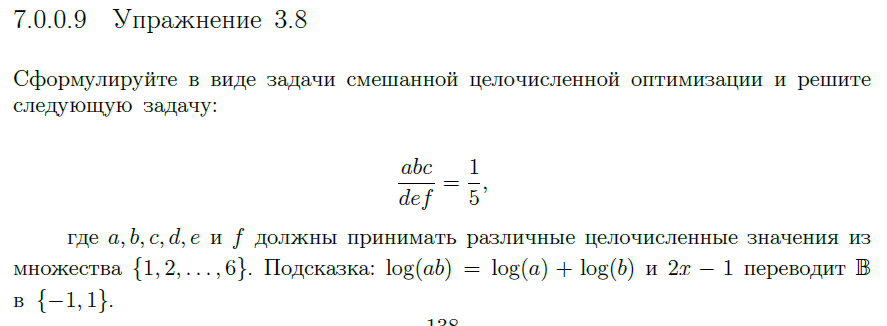

### Формализация 3.8 (Цифры \(abc/def=1/5\))

**Смысл.** Назначить цифры \(\{1,\ldots,6\}\) позициям \(a,\ldots,f\) по одной без повторов так, что \(abc/def=1/5\).

**Переменные.** \(z_{p,k}\in\{0,1\}\): позиция \(p\) получила цифру \(k\).

$$
\begin{align*}
\min\quad &0\\
\text{s.t.}\quad &\sum_k z_{p,k}=1 &&\forall p,\\
&\sum_p z_{p,k}=1 &&\forall k,\\
&\sum_{p\in\{a,b,c\},k} \log k\cdot z_{p,k}
 -\sum_{p\in\{d,e,f\},k} \log k\cdot z_{p,k}
 = -\log 5,\\
& z_{p,k}\in\{0,1\}.
\end{align*}
$$

Логарифм линеаризует произведение. После solve проверяем целочисленно: \(a\cdot b\cdot c\cdot 5 = d\cdot e\cdot f\).


In [17]:
digits = list(range(1, 7))
positions = ["a", "b", "c", "d", "e", "f"]

m38 = pyo.ConcreteModel(name="Digit_product_ratio")
m38.P = pyo.Set(initialize=positions)
m38.K = pyo.Set(initialize=digits)

# z[pos, digit] = 1, если цифра digit назначена позиции pos.
m38.z = pyo.Var(m38.P, m38.K, domain=pyo.Binary)

# В каждой позиции должна быть ровно одна цифра.
m38.one_digit_per_position = pyo.Constraint(
    m38.P, rule=lambda m, pos: sum(m.z[pos, k] for k in m.K) == 1
)

# Каждая цифра 1..6 должна использоваться ровно один раз.
m38.use_each_digit_once = pyo.Constraint(
    m38.K, rule=lambda m, k: sum(m.z[pos, k] for pos in m.P) == 1
)

# Коэффициенты +1 для a,b,c и -1 для d,e,f.
sign = {"a": 1, "b": 1, "c": 1, "d": -1, "e": -1, "f": -1}

# Логарифмируем abc/def = 1/5 → log a+log b+log c - log d - log e - log f = -log 5.
# Используем допуск из-за погрешности float.
log_expr = sum(sign[pos] * np.log(k) * m38.z[pos, k]
               for pos in m38.P for k in m38.K)
m38.ratio_lb = pyo.Constraint(expr=log_expr >= -np.log(5) - 1e-9)
m38.ratio_ub = pyo.Constraint(expr=log_expr <= -np.log(5) + 1e-9)

m38.obj = pyo.Objective(expr=0, sense=pyo.minimize)
res38 = solver.solve(m38)
print("Статус:", res38.solver.termination_condition)

if res38.solver.termination_condition == pyo.TerminationCondition.optimal:
    answer38 = {}
    for pos in positions:
        answer38[pos] = next(k for k in digits if pyo.value(m38.z[pos, k]) > 0.5)
    numerator = answer38["a"] * answer38["b"] * answer38["c"]
    denominator = answer38["d"] * answer38["e"] * answer38["f"]
    print("Найденные цифры:", answer38)
    print("Произведение в числителе:", numerator)
    print("Произведение в знаменателе:", denominator)
    print("Отношение:", numerator / denominator)
    print("Целочисленная проверка a*b*c*5 == d*e*f:",
          numerator * 5 == denominator)
    print("Все цифры 1..6 ровно по разу:",
          sorted(answer38.values()) == digits)

Статус: optimal
Найденные цифры: {'a': 2, 'b': 1, 'c': 6, 'd': 5, 'e': 3, 'f': 4}
Произведение в числителе: 12
Произведение в знаменателе: 60
Отношение: 0.2
Целочисленная проверка a*b*c*5 == d*e*f: True
Все цифры 1..6 ровно по разу: True


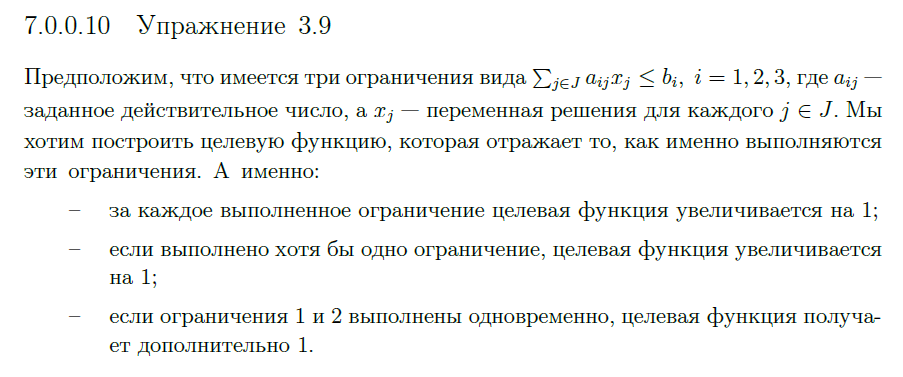

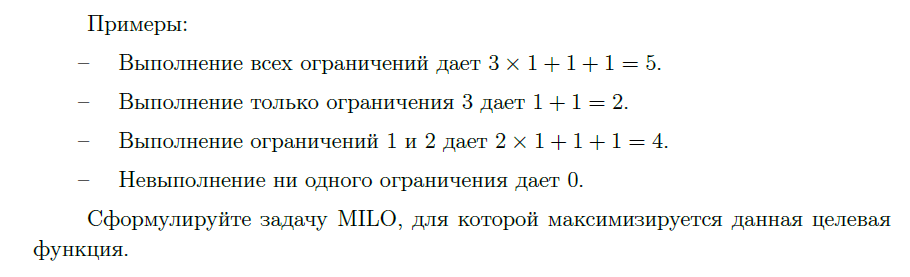

### Формализация 3.9 (Награда за выполнение ограничений)

**Смысл.** Есть три линейных ограничения \(\sum_j a_{ij}x_j\le b_i\). Цель награждает: +1 за каждое выполненное; +1 если выполнено хотя бы одно; +1 если одновременно 1 и 2.

**Переменные.** \(x_j\ge 0\); \(y_i\in\{0,1\}\) — считаем ограничение \(i\) выполненным; \(u\) — «хотя бы одно»; \(v\) — «1 и 2».

$$
\begin{align*}
\max\quad &\sum_{i=1}^3 y_i + u + v\\
\text{s.t.}\quad &\sum_j a_{ij}x_j \le b_i + M_i(1-y_i) &&\forall i\quad\text{(Big-M)},\\
& u\ge y_i,\quad u\le\sum_i y_i,\\
& v\le y_1,\ v\le y_2,\ v\ge y_1+y_2-1,\\
& y_i,u,v\in\{0,1\}.
\end{align*}
$$

Примеры: все → 5; только 3 → 2; 1 и 2 → 4; ничего → 0.


In [18]:
# Демонстрационные данные.
J = [1, 2, 3]
I = [1, 2, 3]
A = {
    (1,1): 2, (1,2): 1, (1,3): 3,
    (2,1): 1, (2,2): 3, (2,3): 1,
    (3,1): 2, (3,2): 2, (3,3): 1,
}
b = {1: 10, 2: 12, 3: 8}
x_upper = {1: 10, 2: 10, 3: 10}
M_big = {}

# Для каждого ограничения считаем безопасное большое M.
# Здесь x[j] >= 0, поэтому верхняя граница левой части равна sum(A[i,j]*upper[j])
# при неотрицательных коэффициентах. Для отрицательных коэффициентов надо отдельно
# вычислять верхнюю границу с учётом нижних и верхних границ x.
for i in I:
    max_lhs = sum(max(0, A[i,j]) * x_upper[j] for j in J)
    M_big[i] = max(0, max_lhs - b[i] + 1)

m39 = pyo.ConcreteModel(name="Objective_from_constraint_satisfaction")
m39.I = pyo.Set(initialize=I)
m39.J = pyo.Set(initialize=J)

m39.x = pyo.Var(m39.J, domain=pyo.NonNegativeReals,
                bounds=lambda m, j: (0, x_upper[j]))
m39.y = pyo.Var(m39.I, domain=pyo.Binary)  # 1, если ограничение засчитано выполненным
m39.any_ok = pyo.Var(domain=pyo.Binary)    # 1, если выполнено хотя бы одно
m39.both_12 = pyo.Var(domain=pyo.Binary)   # 1, если выполнены ограничения 1 и 2

# Если y[i] = 1, исходное ограничение должно выполняться.
# Если y[i] = 0, правая часть ослабляется на M.
def activate_constraint_rule(m, i):
    return sum(A[i,j] * m.x[j] for j in m.J) <= b[i] + M_big[i] * (1 - m.y[i])
m39.logic = pyo.Constraint(m39.I, rule=activate_constraint_rule)

# any_ok равна 1, если хотя бы одна y[i] равна 1.
m39.any_lower = pyo.Constraint(expr=m39.any_ok >= m39.y[1])
m39.any_lower2 = pyo.Constraint(expr=m39.any_ok >= m39.y[2])
m39.any_lower3 = pyo.Constraint(expr=m39.any_ok >= m39.y[3])
m39.any_upper = pyo.Constraint(expr=m39.any_ok <= sum(m39.y[i] for i in m39.I))

# both_12 = y[1] AND y[2].
m39.both_upper1 = pyo.Constraint(expr=m39.both_12 <= m39.y[1])
m39.both_upper2 = pyo.Constraint(expr=m39.both_12 <= m39.y[2])
m39.both_lower = pyo.Constraint(expr=m39.both_12 >= m39.y[1] + m39.y[2] - 1)

# Целевая функция: сумма выполненных ограничений + бонус за любое выполненное
# ограничение + бонус за одновременное выполнение ограничений 1 и 2.
m39.obj = pyo.Objective(
    expr=sum(m39.y[i] for i in m39.I) + m39.any_ok + m39.both_12,
    sense=pyo.maximize
)

solver.solve(m39)
print("Значение целевой функции:", pyo.value(m39.obj))
print("x =", {j: pyo.value(m39.x[j]) for j in m39.J})
print("Флаги выполненных ограничений =", {i: round(pyo.value(m39.y[i])) for i in m39.I})
print("Выполнено хотя бы одно:", round(pyo.value(m39.any_ok)))
print("Выполнены ограничения 1 и 2:", round(pyo.value(m39.both_12)))

Значение целевой функции: 5.0
x = {1: 0.0, 2: 0.0, 3: 0.0}
Флаги выполненных ограничений = {1: 1, 2: 1, 3: 1}
Выполнено хотя бы одно: 1
Выполнены ограничения 1 и 2: 1


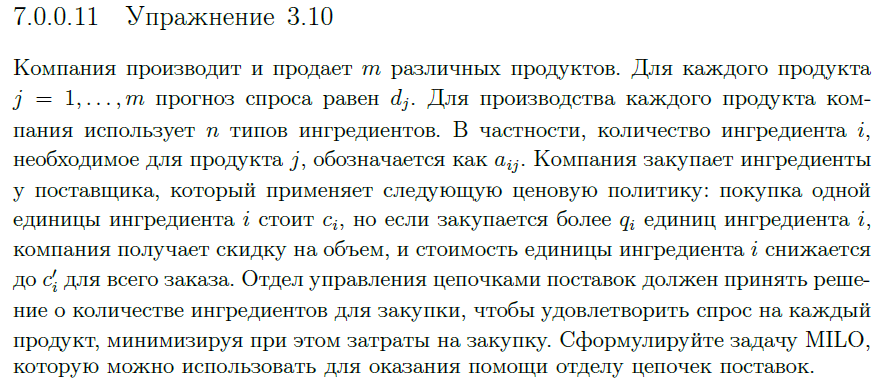

### Формализация 3.10 (Закупка со скидкой all-unit)

**Смысл.** Нужно купить ингредиенты под спрос. Если объём \(x_i>q_i\), вся партия идёт по цене \(c'_i\), иначе по \(c_i\).

**Переменные.** \(x_i\ge 0\) — закупка; \(y_i\in\{0,1\}\) — скидка; \(w_i\approx x_i y_i\).

$$
\begin{align*}
\min\quad &\sum_i\bigl(c_i x_i + (c'_i-c_i)w_i\bigr)\\
\text{s.t.}\quad & x_i \ge \sum_j a_{ij}d_j &&\forall i,\\
& x_i \le q_i + M_i y_i,\\
& x_i \ge q_i+\varepsilon - M_i(1-y_i),\\
& w_i \le x_i,\quad w_i\le M_i y_i,\quad w_i\ge x_i-M_i(1-y_i),\\
& x_i,w_i\ge 0,\ y_i\in\{0,1\}.
\end{align*}
$$


In [19]:
# Количество продуктов и ингредиентов.
m_products = 3
n_ingredients = 2

products = list(range(1, m_products + 1))
ingredients = list(range(1, n_ingredients + 1))

# Демонстрационные данные.
# Спрос на каждый продукт.
demand = {
    1: 100,
    2: 80,
    3: 60
}

# Количество ингредиента i для одной единицы продукта j.
a = {
    (1, 1): 2, (1, 2): 1, (1, 3): 3,
    (2, 1): 1, (2, 2): 2, (2, 3): 1
}

# Обычная цена ингредиента.
c = {
    1: 10,
    2: 8
}

# Цена ингредиента со скидкой.
c_discount = {
    1: 7,
    2: 6
}

# Порог получения скидки.
q = {
    1: 300,
    2: 250
}

# Верхние границы количества закупаемых ингредиентов.
# В реальной задаче их нужно определить из исходных данных.
M = {
    1: 2000,
    2: 2000
}

# Минимальный шаг закупки.
# Здесь предполагается, что ингредиенты закупаются целыми единицами.
eps = 1

# Создаем модель.
m310 = pyo.ConcreteModel(name="Ingredient_purchasing")

m310.I = pyo.Set(initialize=ingredients)
m310.J = pyo.Set(initialize=products)

# x[i] — количество закупаемого ингредиента.
m310.x = pyo.Var(m310.I, domain=pyo.NonNegativeReals)

# y[i] = 1, если получена скидка.
m310.y = pyo.Var(m310.I, domain=pyo.Binary)

# Вспомогательная переменная для учета скидки.
m310.w = pyo.Var(m310.I, domain=pyo.NonNegativeReals)

# Минимизируем общую стоимость закупки.
m310.obj = pyo.Objective(
    expr=sum(
        c[i] * m310.x[i]
        + (c_discount[i] - c[i]) * m310.w[i]
        for i in m310.I
    ),
    sense=pyo.minimize
)

# Ограничение: закупленного ингредиента должно хватить
# для производства всех продуктов в соответствии со спросом.
m310.ingredient_requirements = pyo.Constraint(
    m310.I,
    rule=lambda m, i:
        m.x[i] >= sum(
            a[i, j] * demand[j] for j in m.J
        )
)

# Если скидка не получена (y[i] = 0),
# количество закупки не может превышать порог q[i].
m310.discount_upper = pyo.Constraint(
    m310.I,
    rule=lambda m, i:
        m.x[i] <= q[i] + M[i] * m.y[i]
)

# Если скидка получена (y[i] = 1),
# количество закупки должно превышать порог q[i].
m310.discount_lower = pyo.Constraint(
    m310.I,
    rule=lambda m, i:
        m.x[i] >= q[i] + eps - M[i] * (1 - m.y[i])
)

# Линеаризация произведения w[i] = x[i] * y[i].
m310.linearization_1 = pyo.Constraint(
    m310.I,
    rule=lambda m, i: m.w[i] <= m.x[i]
)

m310.linearization_2 = pyo.Constraint(
    m310.I,
    rule=lambda m, i: m.w[i] <= M[i] * m.y[i]
)

m310.linearization_3 = pyo.Constraint(
    m310.I,
    rule=lambda m, i:
        m.w[i] >= m.x[i] - M[i] * (1 - m.y[i])
)

# Решаем задачу.
result = solver.solve(m310)

# Выводим результаты.
print("\nМинимальные затраты на закупку:",
      round(pyo.value(m310.obj), 2))

print("\nРезультаты закупки:")

for i in m310.I:
    quantity = pyo.value(m310.x[i])
    discount = round(pyo.value(m310.y[i]))

    if discount == 1:
        price = c_discount[i]
        status = "Скидка получена"
    else:
        price = c[i]
        status = "Обычная цена"

    print(
        f"Ингредиент {i}: "
        f"количество = {quantity:.2f}, "
        f"цена за единицу = {price}, "
        f"статус = {status}, "
        f"стоимость = {quantity * price:.2f}"
    )



Минимальные затраты на закупку: 5140.0

Результаты закупки:
Ингредиент 1: количество = 460.00, цена за единицу = 7, статус = Скидка получена, стоимость = 3220.00
Ингредиент 2: количество = 320.00, цена за единицу = 6, статус = Скидка получена, стоимость = 1920.00
